ORIGINAL DATASET
 Study_Hours  Attendance  Assignment_Score  Exam_Score
           2          60                40          45
           4          65                50          50
           6          70                55          60
           8          75                65          65
          10          80                70          75
           3          62                45          48
           5          68                60          58
           7          78                72          70
           9          85                80          82
          12          95                90          95

STATISTICAL SUMMARY
       Study_Hours  Attendance  Assignment_Score  Exam_Score
count        10.00       10.00             10.00       10.00
mean          6.60       73.80             62.70       64.80
std           3.20       10.99             15.80       15.99
min           2.00       60.00             40.00       45.00
25%           4.25       65.75             51.25    

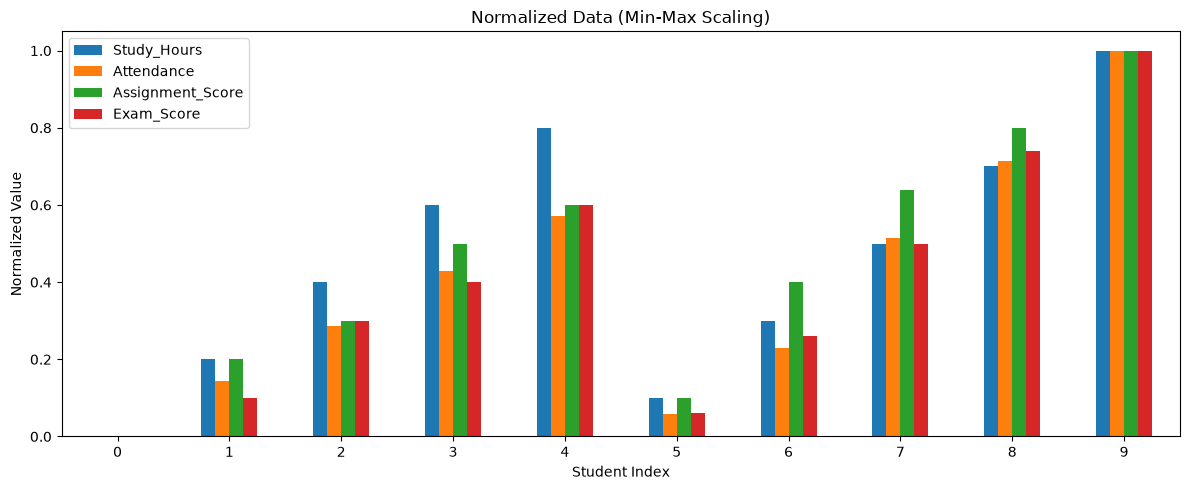


STANDARDIZATION USING STANDARDSCALER

Standardized Dataset:
 Study_Hours  Attendance  Assignment_Score  Exam_Score
       -1.51       -1.32             -1.51       -1.31
       -0.86       -0.84             -0.85       -0.98
       -0.20       -0.36             -0.51       -0.32
        0.46        0.12              0.15        0.01
        1.12        0.59              0.49        0.67
       -1.18       -1.13             -1.18       -1.11
       -0.53       -0.56             -0.18       -0.45
        0.13        0.40              0.62        0.34
        0.79        1.07              1.15        1.13
        1.78        2.03              1.82        1.99

Mean of each feature:
Study_Hours         0.0
Attendance          0.0
Assignment_Score   -0.0
Exam_Score          0.0
dtype: float64

Standard deviation of each feature:
Study_Hours         1.0
Attendance          1.0
Assignment_Score    1.0
Exam_Score          1.0
dtype: float64


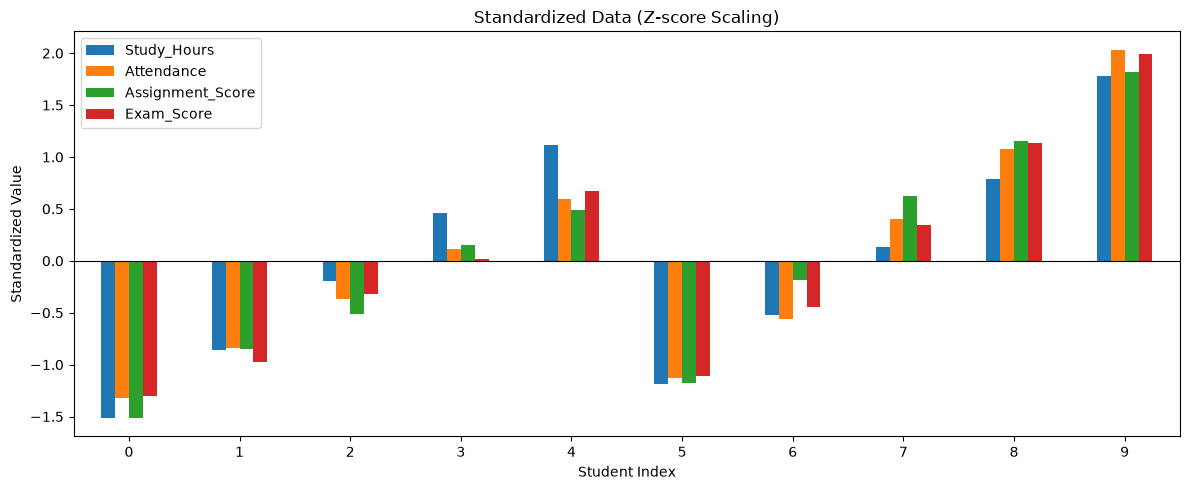


PRINCIPAL COMPONENT ANALYSIS (PCA)

PCA Transformed Data:
  PC1   PC2
-2.83 -0.08
-1.76  0.00
-0.70  0.20
 0.37  0.29
 1.43  0.49
-2.30 -0.03
-0.86 -0.19
 0.75 -0.32
 2.08 -0.28
 3.81 -0.08

Explained Variance Ratio:
[0.9802 0.0147]

Explained Variance Percentage:
[98.02  1.47] %

Total Variance Retained:
0.9949
Total Variance Retained (%): 99.49 %


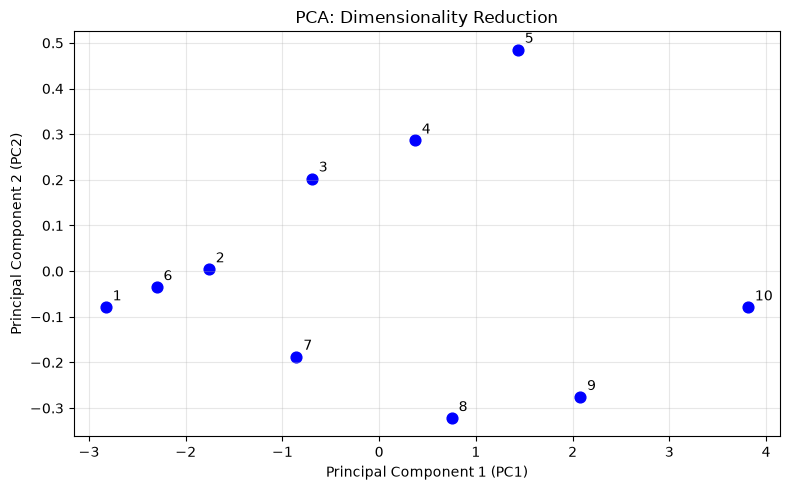


DIMENSIONALITY REDUCTION SUMMARY
Original number of features: 4
Number of PCA components: 2
Variance retained by 2 components: 99.49 %

Program executed successfully!


In [1]:

# Feature Engineering: Normalization, Standardization and PCA

# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

# Step 2: Create a sample dataset
data = {
    'Study_Hours': [2, 4, 6, 8, 10, 3, 5, 7, 9, 12],
    'Attendance': [60, 65, 70, 75, 80, 62, 68, 78, 85, 95],
    'Assignment_Score': [40, 50, 55, 65, 70, 45, 60, 72, 80, 90],
    'Exam_Score': [45, 50, 60, 65, 75, 48, 58, 70, 82, 95]
}

df = pd.DataFrame(data)

# Display original dataset
print("=" * 60)
print("ORIGINAL DATASET")
print("=" * 60)
print(df.to_string(index=False))

print("\nSTATISTICAL SUMMARY")
print(df.describe().round(2))

# Step 3: Normalization using MinMaxScaler
print("\n" + "=" * 60)
print("NORMALIZATION USING MINMAXSCALER")
print("=" * 60)

minmax_scaler = MinMaxScaler()
normalized_data = minmax_scaler.fit_transform(df)

normalized_df = pd.DataFrame(
    normalized_data,
    columns=df.columns
)

print("\nNormalized Dataset:")
print(normalized_df.round(2).to_string(index=False))

print("\nMinimum values:")
print(normalized_df.min().round(2))

print("\nMaximum values:")
print(normalized_df.max().round(2))

# Visualize normalized data
normalized_df.plot(
    kind='bar',
    figsize=(12, 5),
    title='Normalized Data (Min-Max Scaling)'
)
plt.xlabel("Student Index")
plt.ylabel("Normalized Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Step 4: Standardization using StandardScaler
print("\n" + "=" * 60)
print("STANDARDIZATION USING STANDARDSCALER")
print("=" * 60)

standard_scaler = StandardScaler()
standardized_data = standard_scaler.fit_transform(df)

standardized_df = pd.DataFrame(
    standardized_data,
    columns=df.columns
)

print("\nStandardized Dataset:")
print(standardized_df.round(2).to_string(index=False))

print("\nMean of each feature:")
print(standardized_df.mean().round(2))

print("\nStandard deviation of each feature:")
print(standardized_df.std(ddof=0).round(2))

# Visualize standardized data
standardized_df.plot(
    kind='bar',
    figsize=(12, 5),
    title='Standardized Data (Z-score Scaling)'
)
plt.xlabel("Student Index")
plt.ylabel("Standardized Value")
plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Step 5: Apply PCA for dimensionality reduction
print("\n" + "=" * 60)
print("PRINCIPAL COMPONENT ANALYSIS (PCA)")
print("=" * 60)

# PCA should be applied after standardizing the features
pca = PCA(n_components=2)
pca_data = pca.fit_transform(standardized_data)

pca_df = pd.DataFrame(
    pca_data,
    columns=['PC1', 'PC2']
)

print("\nPCA Transformed Data:")
print(pca_df.round(2).to_string(index=False))

# Step 6: Display explained variance
print("\nExplained Variance Ratio:")
print(np.round(pca.explained_variance_ratio_, 4))

print("\nExplained Variance Percentage:")
print(
    np.round(pca.explained_variance_ratio_ * 100, 2),
    "%"
)

total_variance = pca.explained_variance_ratio_.sum()

print("\nTotal Variance Retained:")
print(round(total_variance, 4))

print("Total Variance Retained (%):",
      round(total_variance * 100, 2), "%")

# Step 7: Visualize PCA output
plt.figure(figsize=(8, 5))

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    color='blue',
    s=60
)

# Label each data point
for i in range(len(pca_df)):
    plt.annotate(
        str(i + 1),
        (pca_df['PC1'].iloc[i], pca_df['PC2'].iloc[i]),
        xytext=(5, 5),
        textcoords='offset points'
    )

plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.title("PCA: Dimensionality Reduction")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Step 8: Final comparison
print("\n" + "=" * 60)
print("DIMENSIONALITY REDUCTION SUMMARY")
print("=" * 60)

print("Original number of features:", df.shape[1])
print("Number of PCA components:", pca_df.shape[1])
print(
    "Variance retained by 2 components:",
    round(total_variance * 100, 2), "%"
)

print("\nProgram executed successfully!")
